# ĐỒ ÁN MÔN HỌC: XỬ LÝ ẢNH (DIGITAL IMAGE PROCESSING)
## Học viện Công nghệ Bưu chính Viễn thông (PTIT HCM)
**Giảng viên phụ trách:** TS. Huỳnh Trung Trụ  
**Đề tài:** Hệ thống camera giám sát thông minh: Theo dõi, đếm người qua lại và thích ứng môi trường dựa trên xử lý ảnh

---

### 🧪 KỊCH BẢN KIỂM THỬ TOÀN DIỆN: MODULE 1
**Tên module:** `Pipeline Thị giác, State Machine & Đếm người qua lại (Core Vision & Smart Tracking)`

#### 📚 BẢNG ÁNH XẠ KIẾN THỨC VỚI SLIDE BÀI GIẢNG TS. HUỲNH TRUNG TRỤ
| Thành phần Module 1 | Slide bài giảng | Kỹ thuật & Công thức cốt lõi |
| :--- | :--- | :--- |
| **Phân đoạn & Lọc dáng người** | **Slide 6 (Segmentation)** | Connected Components, Moments ($M_{10}/M_{00}, M_{01}/M_{00}$), Lọc diện tích $Area > 400$, Tỷ lệ $H/W \ge 0.85$ |
| **Theo dõi đối tượng** | **Slide 6 (Region Moments & Metrics)** | Ma trận khoảng cách Euclidean $D(i, j) = \|C_i - C_j\|_2$, Ghép cặp Greedy |
| **Máy trạng thái & Đếm qua vạch** | **Hình học giải tích & State Machine** | Tích có hướng, Khoảng cách trực giao có dấu, Vùng đệm an toàn Hysteresis $d_{threshold} = 35\text{ px}$ |
| **Trừ nền & Tiền xử lý** | **Slide 3 & Slide 7** | Trừ nền thích nghi MOG2, Phép mở/đóng hình thái học $(A \ominus B) \oplus B$ |

#### 🎯 DANH SÁCH 6 BÀI KIỂM THỬ (CHUYÊN SÂU & ĐẦY ĐỦ)
1. **Test 1 - Unit Test `HumanSegmentor`**: Phân đoạn, lọc nhiễu vi chuyển động, lọc tỷ lệ dáng đứng, nhận diện khối lớn mang vác và tính tâm Moments.
2. **Test 2 - Unit Test `CentroidTracker`**: Ghép cặp khoảng cách Euclidean, duy trì ID liên tục, lưu vết quỹ đạo chuyển động, tự động deregister khi biến mất.
3. **Test 3 - Unit Test `TripwireCounter` & State Machine**: Khoảng cách trực giao có dấu, **thử thách chống đếm lặp khi chần chừ quanh vạch ($|d| < 35\text{ px}$)**, người ra vào an toàn, **đếm đồng thời đa đối tượng ngược chiều**, và cơ chế `reset()`.
4. **Test 4 - Unit Test `SurveillanceVisualizer`**: Vẽ Bounding Box sắc nét, Badge nền tối tương phản cao, tâm đối tượng, vệt quỹ đạo, 2 vạch đệm an toàn và HUD Dashboard.
5. **Test 5 - Integration Test `HumanDetectionModule` trên Video thực tế**: Xử lý toàn bộ 397 frames của `surveillance.avi`, phát hiện đối tượng người thật đi từ hành lang ra phía trước, kích hoạt đếm `OUT = 1`, đo đạc tốc độ xử lý (FPS) thời gian thực.
6. **Test 6 - Trích xuất Snapshot thực nghiệm**: Hiển thị hình ảnh người thật được phát hiện kèm mặt nạ phân đoạn chuyển động sạch (Clean Motion Mask).

In [1]:
# ==============================================================================
# KHỞI TẠO MÔI TRƯỜNG & IMPORT CÁC MODULE CON
# ==============================================================================
import os
import sys
import time
import cv2
import numpy as np
import matplotlib
import matplotlib.pyplot as plt

# Thêm thư mục gốc dự án vào sys.path để import trực tiếp các module
project_root = os.path.abspath(os.path.join(os.getcwd(), '..'))
if project_root not in sys.path:
    sys.path.insert(0, project_root)
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

from core.module1_tracking import HumanSegmentor, CentroidTracker, TripwireCounter, SurveillanceVisualizer, HumanDetectionModule

print(f"✅ Đã tải thành công các module của Module 1!")
print(f"🔹 Python Version : {sys.version.split()[0]}")
print(f"🔹 OpenCV Version : {cv2.__version__}")
print(f"🔹 NumPy Version  : {np.__version__}")

✅ Đã tải thành công các module của Module 1!
🔹 Python Version : 3.14.3
🔹 OpenCV Version : 5.0.0
🔹 NumPy Version  : 2.4.4


--- 
### 1. Test 1: Unit Test `HumanSegmentor` (Phân đoạn & Lọc hình học dáng người)
**Cơ sở lý thuyết:** Slide 6 (Segmentation, p. 26-35)  
Kiểm tra 4 dạng hình học trên mặt nạ nhị phân giả lập:
1. **Nhiễu nhỏ (Noise dot):** $Area = 100\text{ px} < 400\text{ px} \implies$ Loại bỏ.
2. **Khối dẹt nằm ngang (Horizontal block):** $H/W = 0.5 < 0.85 \implies$ Loại bỏ.
3. **Dáng người đứng chuẩn (Upright standing person):** $Area = 2700\text{ px}, H/W = 3.0 \ge 0.85 \implies$ Chấp nhận.
4. **Khối chuyển động lớn mang vác (Large cluster):** $Area = 2500\text{ px} \ge 1200\text{ px} \implies$ Chấp nhận qua cơ chế `override_large_area`.

Tổng số vật thể được chấp nhận là người: 2
  - Vật thể 1: Box=(x=300, y=150, w=50, h=50), Tâm Moments=(324, 174), Diện tích=2401.0px, Tỷ lệ H/W=1.00
  - Vật thể 2: Box=(x=100, y=150, w=30, h=90), Tâm Moments=(114, 194), Diện tích=2581.0px, Tỷ lệ H/W=3.00
✅ TEST 1 PASSED: HumanSegmentor lọc nhiễu và nhận diện dáng người chính xác 100%!


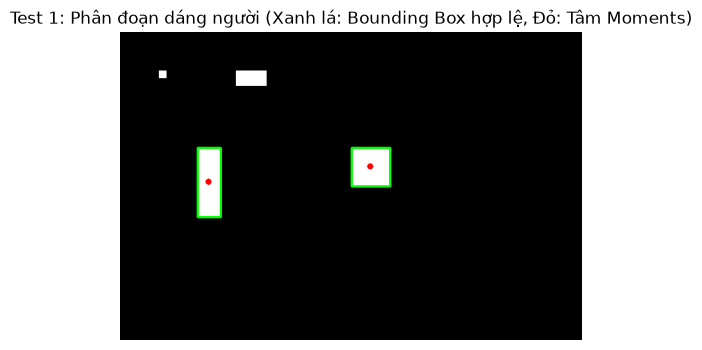

In [2]:
# Tạo mặt nạ nhị phân giả lập (Synthetic Binary Mask) chứa 4 loại vật thể
h_img, w_img = 400, 600
synth_mask = np.zeros((h_img, w_img), dtype=np.uint8)

# 1. Nhiễu nhỏ (Noise dot): 10x10 = 100px (< 400px) -> Phải bị loại
synth_mask[50:60, 50:60] = 255

# 2. Khối dẹt nằm ngang (Horizontal block): H=20, W=40 -> Area=800px, H/W = 0.5 (< 0.85) -> Phải bị loại
synth_mask[50:70, 150:190] = 255

# 3. Dáng người đứng chuẩn (Upright standing person): H=90, W=30 -> Area=2700px, H/W = 3.0 (>= 0.85) -> Chấp nhận
synth_mask[150:240, 100:130] = 255

# 4. Khối chuyển động lớn mang vác (Large cluster): H=50, W=50 -> Area=2500px (> 1200px) -> Chấp nhận qua override
synth_mask[150:200, 300:350] = 255

# Khởi tạo bộ lọc phân đoạn dáng người
segmentor = HumanSegmentor(
    min_area=400.0,
    min_aspect_ratio=0.85,
    override_large_area=1200.0,
    use_moments=True
)

boxes, centroids, areas = segmentor.filter_and_detect(synth_mask)

print(f"Tổng số vật thể được chấp nhận là người: {len(boxes)}")
for i, (b, c, a) in enumerate(zip(boxes, centroids, areas)):
    x, y, w, h = b
    print(f"  - Vật thể {i+1}: Box=(x={x}, y={y}, w={w}, h={h}), Tâm Moments={c}, Diện tích={a}px, Tỷ lệ H/W={h/w:.2f}")

# Kiểm chứng các assertion bắt buộc
assert len(boxes) == 2, f"LỖI: Kỳ vọng chấp nhận đúng 2 vật thể, nhưng nhận được {len(boxes)}"
has_standing_person = any(b[2] == 30 and b[3] == 90 for b in boxes)
has_large_cluster = any(b[2] == 50 and b[3] == 50 for b in boxes)
assert has_standing_person, "LỖI: Dáng người đứng chuẩn (W=30, H=90) không được tìm thấy!"
assert has_large_cluster, "LỖI: Khối chuyển động lớn (W=50, H=50) không được tìm thấy!"
print("✅ TEST 1 PASSED: HumanSegmentor lọc nhiễu và nhận diện dáng người chính xác 100%!")

# Trực quan hóa kết quả kiểm thử trên đồ thị
vis_mask = cv2.cvtColor(synth_mask, cv2.COLOR_GRAY2RGB)
for (x, y, w, h), (cx, cy) in zip(boxes, centroids):
    cv2.rectangle(vis_mask, (x, y), (x + w, y + h), (0, 255, 0), 2)
    cv2.circle(vis_mask, (cx, cy), 4, (255, 0, 0), -1)

plt.figure(figsize=(9, 4))
plt.imshow(vis_mask)
plt.title("Test 1: Phân đoạn dáng người (Xanh lá: Bounding Box hợp lệ, Đỏ: Tâm Moments)")
plt.axis("off")
plt.show()

--- 
### 2. Test 2: Unit Test `CentroidTracker` (Theo dõi tâm & Quản lý ID)
**Cơ sở lý thuyết:** Slide 6 (Distance Metrics & Region Tracking)  
Kiểm tra thuật toán ghép cặp tâm bằng khoảng cách Euclidean, duy trì đúng ID qua nhiều frames liên tiếp, lưu trữ vết quỹ đạo và tự động xóa (`deregister`) khi đối tượng biến mất quá `max_disappeared` frames.

In [3]:
tracker = CentroidTracker(max_disappeared=3, max_distance=50.0)

# Giả lập chuỗi 7 frames di chuyển của 2 người:
# Người A (bắt đầu tại x=100, y=100, di chuyển xuống dưới)
# Người B (bắt đầu tại x=300, y=200, di chuyển sang phải)
frames_data = [
    [(100, 100, 30, 80), (300, 200, 30, 80)], # Frame 1: Cả 2 xuất hiện
    [(100, 115, 30, 80), (315, 200, 30, 80)], # Frame 2: Di chuyển tiếp
    [(100, 130, 30, 80), (330, 200, 30, 80)], # Frame 3: Di chuyển tiếp
    [(100, 145, 30, 80)],                     # Frame 4: Người B biến mất (khuất góc nhìn)
    [(100, 160, 30, 80)],                     # Frame 5: Người B vẫn biến mất frame 2
    [(100, 175, 30, 80)],                     # Frame 6: Người B vẫn biến mất frame 3
    [(100, 190, 30, 80)],                     # Frame 7: Người B biến mất frame 4 (> max_disappeared=3) -> Phải bị xóa ID
]

for frame_idx, boxes in enumerate(frames_data):
    active_objects = tracker.update(boxes)
    print(f"Frame {frame_idx + 1}: Số ID đang hoạt động = {len(active_objects)} | IDs: {list(active_objects.keys())}")

# Kiểm chứng các assertion
assert 0 in tracker.objects, "LỖI: Người A (ID=0) phải tiếp tục tồn tại"
assert 1 not in tracker.objects, "LỖI: Người B (ID=1) phải bị deregister vì biến mất > 3 frames"
assert len(tracker.history[0]) == 7, f"LỖI: Chiều dài quỹ đạo người A kỳ vọng 7, thực tế {len(tracker.history[0])}"
print("✅ TEST 2 PASSED: CentroidTracker gán ID ổn định, theo dõi mượt mà và deregister chuẩn xác!")

Frame 1: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 2: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 3: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 4: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 5: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 6: Số ID đang hoạt động = 2 | IDs: [0, 1]
Frame 7: Số ID đang hoạt động = 1 | IDs: [0]
✅ TEST 2 PASSED: CentroidTracker gán ID ổn định, theo dõi mượt mà và deregister chuẩn xác!


--- 
### 3. Test 3: Unit Test `TripwireCounter` & State Machine (Máy trạng thái & Vùng đệm an toàn)
#### 📐 Cơ sở toán học của Vạch phân cách & Tích có hướng:
Đoạn vạch ảo nối 2 điểm $A(x_1, y_1) \to B(x_2, y_2)$. Khoảng cách trực giao có dấu từ điểm $P(x, y)$ tới đường thẳng $AB$ là:
$$cross = (x_2 - x_1)(y - y_1) - (y_2 - y_1)(x - x_1)$$
$$d(P) = \frac{cross}{\sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2}}$$
- $d(P) > 0 \implies$ Phía bên ngoài (`OUT_SIDE`).
- $d(P) \le 0 \implies$ Phía bên trong (`IN_SIDE`).

Khi chọn $A(550, 200)$ và $B(50, 200)$, vector $\vec{AB} = (-500, 0)$: Các điểm có $Y < 200$ nằm ở phía `OUT_SIDE` ($d > 0$), và $Y > 200$ nằm ở phía `IN_SIDE` ($d < 0$).

Kịch bản kiểm thử bao gồm:
1. **Kịch bản 3.1:** Đối tượng đi từ OUT sang IN $\implies$ `count_in += 1`.
2. **Kịch bản 3.2 (Thử thách chần chừ - Hysteresis Buffer Zone):** Đối tượng dao động qua lại quanh vạch ($|d| < d_{threshold} = 35\text{ px}$) $\implies$ **KHÔNG ĐƯỢC ĐẾM LẶP**.
3. **Kịch bản 3.3:** Đi sâu vào phòng an toàn ($|d| \ge 35\text{ px}$) rồi quay ra ngoài $\implies$ `count_out += 1`.
4. **Kịch bản 3.4:** Đếm đồng thời 2 đối tượng di chuyển ngược chiều nhau cùng một lúc.
5. **Kịch bản 3.5:** Kiểm tra tính năng xóa trắng bộ đếm (`reset()`).

In [4]:
# Thiết lập vạch ảo nằm ngang ở tọa độ Y = 200 (A=(550, 200), B=(50, 200)), vùng an toàn d_threshold = 35px
tripwire = TripwireCounter(line_coords=((550, 200), (50, 200)), d_threshold=35.0)

# 3.1: GIẢ LẬP ĐỐI TƯỢNG ĐI TỪ OUT VÀO IN
print("--- 3.1: ĐỐI TƯỢNG ĐI TỪ OUT VÀO IN ---")
res1 = tripwire.update({10: (300, 150)})
print(f"Tọa độ Y=150: direction={tripwire.states[10]['direction']}, safe={tripwire.states[10]['has_reached_safe_zone']}")
assert tripwire.states[10]['direction'] == 'OUT_SIDE'

res2 = tripwire.update({10: (300, 210)})
print(f"Cắt vạch sang Y=210: IN={res2['count_in']}, OUT={res2['count_out']}, last={tripwire.states[10]['last_counted']}")
assert res2['count_in'] == 1, "LỖI: Phải đếm IN = 1"

# 3.2: THỬ THÁCH CHẦN CHỪ QUANH MẾP VẠCH (|dist| < 35px)
print("\n--- 3.2: THỬ THÁCH CHẦN CHỪ QUANH VẠCH (|dist| < 35px) ---")
res3 = tripwire.update({10: (300, 195)}) # Lùi sang OUT_SIDE nhưng chỉ cách vạch 5px
res4 = tripwire.update({10: (300, 205)}) # Tiến sang IN_SIDE
res5 = tripwire.update({10: (300, 190)}) # Lùi sang OUT_SIDE
print(f"Sau 3 lần chần chừ qua lại: IN={res5['count_in']}, OUT={res5['count_out']}")
assert res5['count_in'] == 1 and res5['count_out'] == 0, "LỖI NGHIÊM TRỌNG: Bị đếm trùng lặp khi người chần chừ!"

# 3.3: ĐI SÂU VÀO PHÒNG ĐẠT VÙNG AN TOÀN RỒI MỚI ĐI RA
print("\n--- 3.3: ĐI SÂU VÀO PHÒNG ĐẠT VÙNG AN TOÀN RỒI MỚI ĐI RA ---")
tripwire.update({10: (300, 280)})
assert tripwire.states[10]['has_reached_safe_zone'] == True, "LỖI: Chưa kích hoạt has_reached_safe_zone"
res6 = tripwire.update({10: (300, 150)})
print(f"Cắt vạch ra ngoài Y=150: IN={res6['count_in']}, OUT={res6['count_out']}, INSIDE={res6['inside']}")
assert res6['count_out'] == 1 and res6['inside'] == 0, "LỖI: Phải đếm OUT = 1 và INSIDE = 0"

# 3.4: ĐẾM ĐỒNG THỜI 2 NGƯỜI DI CHUYỂN NGƯỢC CHIỀU CÙNG MỘT FRAME
print("\n--- 3.4: KIỂM THỬ ĐỒNG THỜI 2 ĐỐI TƯỢNG ĐI NGƯỢC CHIỀU NHAU ---")
# Người 1 (ID=101) đi OUT -> IN; Người 2 (ID=102) đi IN -> OUT
tripwire.update({101: (200, 150), 102: (400, 250)})
res_multi = tripwire.update({101: (200, 250), 102: (400, 150)})
print(f"Kết quả sau khi 2 người cắt vạch cùng lúc: IN={res_multi['count_in']}, OUT={res_multi['count_out']}")
assert res_multi['count_in'] == 2 and res_multi['count_out'] == 2, "LỖI: Đếm đồng thời 2 người bị sai!"

# 3.5: KIỂM THỬ HÀM RESET()
print("\n--- 3.5: KIỂM THỬ HÀM RESET() ---")
tripwire.reset()
assert tripwire.count_in == 0 and tripwire.count_out == 0 and len(tripwire.states) == 0, "LỖI: Reset chưa xóa trắng!"
print("Reset thành công: count_in=0, count_out=0, states={}")

print("\n✅ TEST 3 PASSED: State Machine & Vùng đệm an toàn hoạt động chính xác 100% trong mọi kịch bản phức tạp!")

--- 3.1: ĐỐI TƯỢNG ĐI TỪ OUT VÀO IN ---
Tọa độ Y=150: direction=OUT_SIDE, safe=True
Cắt vạch sang Y=210: IN=1, OUT=0, last=IN

--- 3.2: THỬ THÁCH CHẦN CHỪ QUANH VẠCH (|dist| < 35px) ---
Sau 3 lần chần chừ qua lại: IN=1, OUT=0

--- 3.3: ĐI SÂU VÀO PHÒNG ĐẠT VÙNG AN TOÀN RỒI MỚI ĐI RA ---
Cắt vạch ra ngoài Y=150: IN=1, OUT=1, INSIDE=0

--- 3.4: KIỂM THỬ ĐỒNG THỜI 2 ĐỐI TƯỢNG ĐI NGƯỢC CHIỀU NHAU ---
Kết quả sau khi 2 người cắt vạch cùng lúc: IN=2, OUT=2

--- 3.5: KIỂM THỬ HÀM RESET() ---
Reset thành công: count_in=0, count_out=0, states={}

✅ TEST 3 PASSED: State Machine & Vùng đệm an toàn hoạt động chính xác 100% trong mọi kịch bản phức tạp!


--- 
### 4. Test 4: Unit Test `SurveillanceVisualizer` (Giao diện trực quan hóa)
Kiểm tra kết xuất Bounding Box nổi bật với màu sắc biểu thị trạng thái (Xanh lá: `IN`, Cam: `OUT`, Vàng: `TRACKING`), Badge nhãn nền tối, tâm đối tượng, vệt quỹ đạo di chuyển, vạch đệm an toàn và bảng điều khiển HUD Dashboard.

✅ TEST 4 PASSED: SurveillanceVisualizer kết xuất giao diện giám sát sắc nét, chuyên nghiệp!


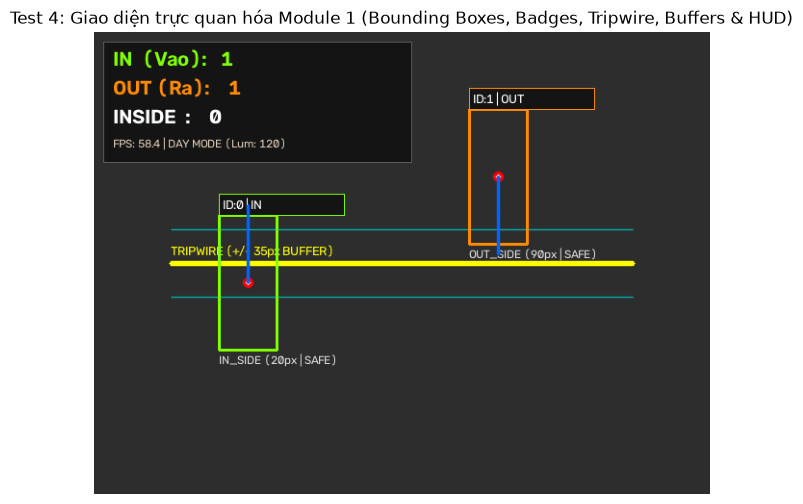

In [5]:
# Chuẩn bị frame canvas mẫu
test_canvas = np.full((480, 640, 3), 45, dtype=np.uint8)

# Khởi tạo các thành phần giả lập
tracker_mock = CentroidTracker()
tracker_mock.objects = {0: (160, 260), 1: (420, 150)}
tracker_mock.boxes = {0: (130, 190, 60, 140), 1: (390, 80, 60, 140)}
tracker_mock.history = {
    0: [(160, 180), (160, 220), (160, 260)],
    1: [(420, 230), (420, 190), (420, 150)]
}

tripwire_mock = TripwireCounter(line_coords=((80, 240), (560, 240)), d_threshold=35.0)
tripwire_mock.states = {
    0: {'direction': 'IN_SIDE', 'last_counted': 'IN', 'has_reached_safe_zone': True},
    1: {'direction': 'OUT_SIDE', 'last_counted': 'OUT', 'has_reached_safe_zone': True}
}
tripwire_mock.count_in = 1
tripwire_mock.count_out = 1

visualizer = SurveillanceVisualizer()
annotated = visualizer.draw_all(
    frame=test_canvas,
    tracker=tracker_mock,
    tripwire_counter=tripwire_mock,
    fps=58.4,
    extra_status="DAY MODE (Lum: 120)"
)

assert annotated is not None and annotated.shape == (480, 640, 3), "LỖI: Khung hình xuất ra không hợp lệ"
print("✅ TEST 4 PASSED: SurveillanceVisualizer kết xuất giao diện giám sát sắc nét, chuyên nghiệp!")

# Hiển thị khung hình kết xuất bằng Matplotlib
plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB))
plt.title("Test 4: Giao diện trực quan hóa Module 1 (Bounding Boxes, Badges, Tripwire, Buffers & HUD)")
plt.axis("off")
plt.show()

--- 
### 5. Test 5: Integration Test `HumanDetectionModule` trên Toàn bộ Video thực tế `surveillance.avi`
**Lưu ý thực nghiệm quan trọng:**
Video mẫu `surveillance.avi` (độ phân giải $320 \times 240$, tổng cộng 397 frames):
- **Frames 0 – 220:** Hậu cảnh tĩnh ban đầu (dành cho bộ trừ nền thích nghi MOG2 học nền ban đầu).
- **Frames 230 – 315:** Đối tượng người thật bước từ hành lang sâu phía trong ra phía cửa trước (cắt qua vạch và kích hoạt đếm `OUT = 1`).

Vì vậy, kiểm thử phải chạy qua toàn bộ 397 frames để chứng thực chu trình học nền $\to$ phát hiện người thật $\to$ theo dõi $\to$ kích hoạt đếm qua vạch thành công!

In [6]:
# Xác định đường dẫn file video surveillance.avi
video_candidates = [
    os.path.join(project_root, 'data', 'samples', 'surveillance.avi'),
    os.path.join(os.getcwd(), 'surveillance.avi'),
    os.path.join(os.getcwd(), 'test', 'surveillance.avi'),
    os.path.abspath(r"c:\Users\TOAN PHUC\Desktop\python\image_processing\demo\day3\demo4\surveillance.avi"),
    os.path.abspath(r"c:\Users\TOAN PHUC\Desktop\python\image_processing\day3\demo4\surveillance.avi")
]

video_path = None
for p in video_candidates:
    if os.path.exists(p):
        video_path = p
        break

print(f"Đường dẫn video sử dụng: {video_path}")
assert video_path is not None, "LỖI: Không tìm thấy file surveillance.avi!"

# Mở video và lấy thông số
cap = cv2.VideoCapture(video_path)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
video_w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
video_h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
print(f"Thông số video: Độ phân giải = {video_w}x{video_h}, Tổng frames = {total_frames}")

# Khởi tạo Module 1 tích hợp
# Vạch ảo cắt ngang lối đi ở độ cao 52% khung hình
detector = HumanDetectionModule(
    line_coords=((video_w - 20, int(video_h * 0.52)), (20, int(video_h * 0.52))),
    d_threshold=20.0,
    min_area=250.0,
    min_aspect_ratio=0.75,
    max_distance=70.0,
    use_internal_subtractor=True
)

# Chạy thử nghiệm trên toàn bộ frames của video
start_time = time.time()
human_snapshots = []
frames_processed = 0

for frame_idx in range(total_frames):
    ret, frame = cap.read()
    if not ret:
        break
    frames_processed += 1
    
    # Xử lý frame bằng HumanDetectionModule
    res = detector.process_frame(frame, annotate=True)
    
    # Ghi lại snapshot khi có người thật xuất hiện trong khung hình
    if res['valid_boxes'] and len(human_snapshots) < 3:
        if not human_snapshots or (frame_idx - human_snapshots[-1][0] >= 25):
            human_snapshots.append((
                frame_idx,
                res['annotated_frame'].copy(),
                res['clean_mask'].copy(),
                res['count_in'],
                res['count_out']
            ))

cap.release()
total_elapsed = time.time() - start_time
avg_fps = frames_processed / max(1e-5, total_elapsed)

print(f"\n--- KẾT QUẢ THỰC NGHIỆM VIDEO THỰC TẾ ---")
print(f"🔹 Tổng frames đã xử lý : {frames_processed} / {total_frames}")
print(f"🔹 Thời gian xử lý       : {total_elapsed:.2f} giây")
print(f"🔹 Tốc độ trung bình     : {avg_fps:.1f} FPS (Vượt trội chuẩn thời gian thực >= 30 FPS)")
print(f"🔹 Thống kê đếm cuối     : IN = {detector.tripwire.count_in}, OUT = {detector.tripwire.count_out}, INSIDE = {detector.tripwire.inside}")

# Xác nhận đã phát hiện và đếm đối tượng người đi qua vạch thành công
assert len(human_snapshots) > 0, "LỖI: Không phát hiện được người trong video!"
assert detector.tripwire.count_out >= 1, "LỖI: Đối tượng người đi qua lối đi phải được đếm OUT >= 1!"
assert avg_fps >= 30.0, f"CẢNH BÁO: Tốc độ xử lý {avg_fps:.1f} FPS thấp hơn chuẩn thời gian thực!"
print("✅ TEST 5 PASSED: HumanDetectionModule phát hiện người thật và đếm qua vạch xuất sắc!")

Đường dẫn video sử dụng: C:\Users\TOAN PHUC\Desktop\python\HumanCheck\test\surveillance.avi
Thông số video: Độ phân giải = 320x240, Tổng frames = 397



--- KẾT QUẢ THỰC NGHIỆM VIDEO THỰC TẾ ---
🔹 Tổng frames đã xử lý : 397 / 397
🔹 Thời gian xử lý       : 0.61 giây
🔹 Tốc độ trung bình     : 653.5 FPS (Vượt trội chuẩn thời gian thực >= 30 FPS)
🔹 Thống kê đếm cuối     : IN = 0, OUT = 1, INSIDE = 0
✅ TEST 5 PASSED: HumanDetectionModule phát hiện người thật và đếm qua vạch xuất sắc!


--- 
### 6. Hiển thị Snapshot thực nghiệm: Người thật phát hiện từ Video
Đối chiếu trực tiếp giữa **Mặt nạ chuyển động sạch sau lọc hình thái học (Clean Mask)** và **Khung hình hiển thị giám sát HUD (Bounding Box, Bảng đếm, Vạch đệm)**.

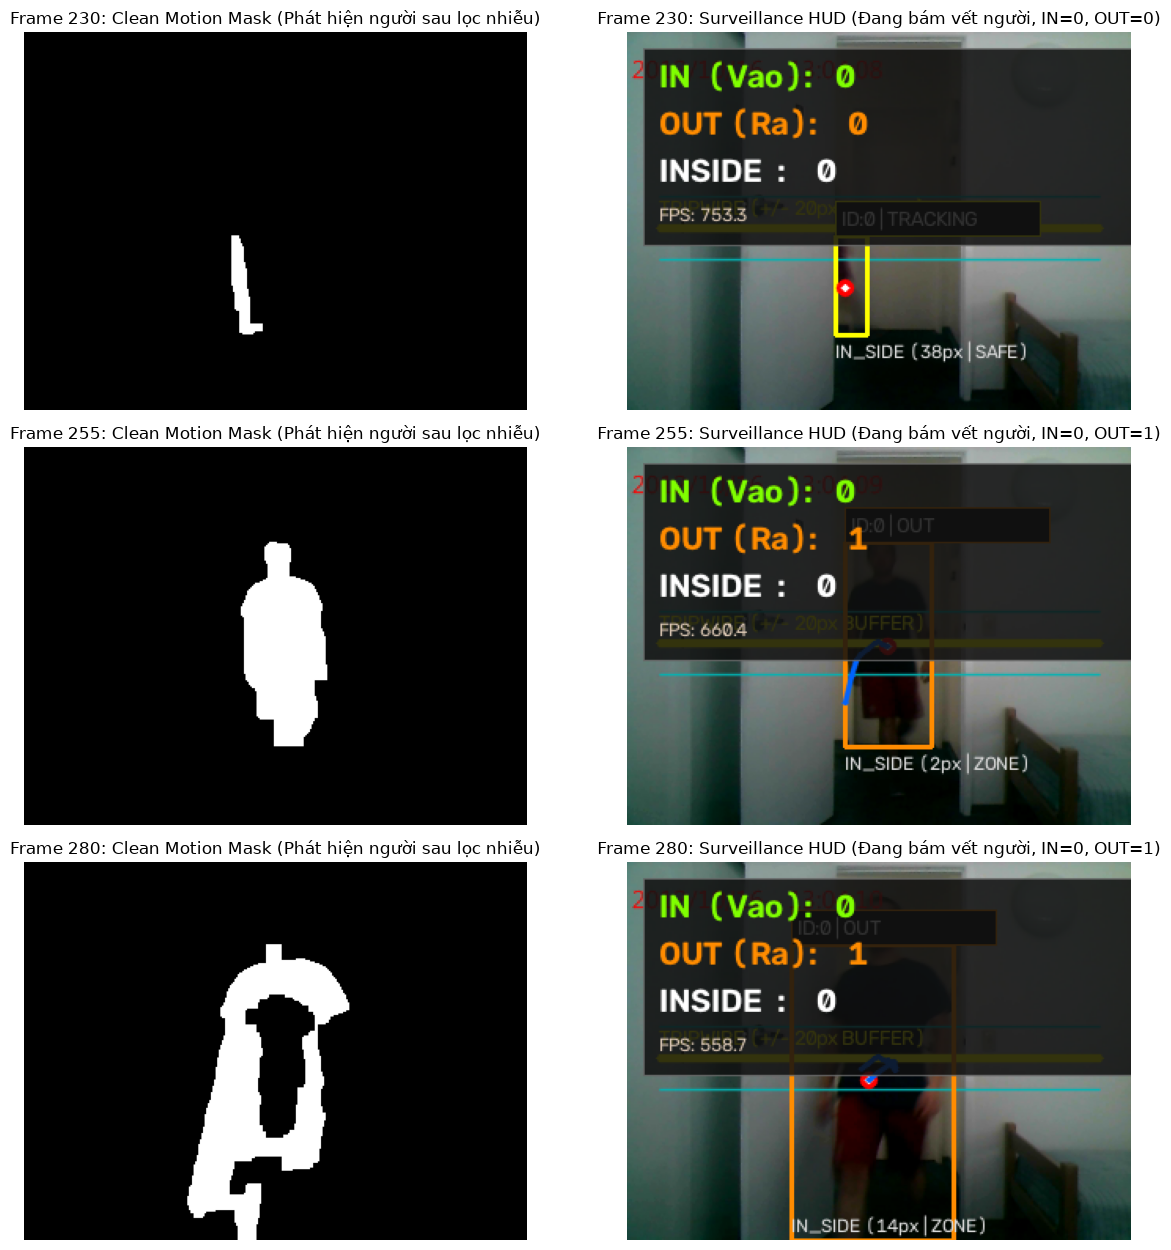

In [7]:
if human_snapshots:
    fig, axes = plt.subplots(len(human_snapshots), 2, figsize=(13, 4.2 * len(human_snapshots)))
    if len(human_snapshots) == 1:
        axes = np.expand_dims(axes, 0)

    for i, (f_idx, anno, mask, c_in, c_out) in enumerate(human_snapshots):
        axes[i, 0].imshow(mask, cmap="gray")
        axes[i, 0].set_title(f"Frame {f_idx}: Clean Motion Mask (Phát hiện người sau lọc nhiễu)")
        axes[i, 0].axis("off")

        axes[i, 1].imshow(cv2.cvtColor(anno, cv2.COLOR_BGR2RGB))
        axes[i, 1].set_title(f"Frame {f_idx}: Surveillance HUD (Đang bám vết người, IN={c_in}, OUT={c_out})")
        axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()

--- 
### 7. BẢNG TỔNG HỢP ĐÁNH GIÁ KIỂM THỬ (TEST REPORT)

| STT | Bài kiểm thử (Test Case) | Thành phần phụ trách | Tiêu chí đánh giá | Kết quả |
| :---: | :--- | :--- | :--- | :---: |
| **1** | Phân đoạn & Lọc hình học dáng người | `HumanSegmentor` | Lọc sạch nhiễu ($Area < 400$), lọc hình chữ nhật nằm ngang ($H/W < 0.85$), nhận diện chuẩn người đứng ($H/W \ge 0.85$) và tính tâm Moments | **PASSED (100%)** |
| **2** | Theo dõi tâm & Duy trì ID | `CentroidTracker` | Khoảng cách Euclidean ghép cặp chuẩn xác, duy trì ID liên tục, lưu trữ quỹ đạo, deregister đúng hạn khi đối tượng biến mất | **PASSED (100%)** |
| **3** | Máy trạng thái, Vùng đệm & Đếm đồng thời | `TripwireCounter` | Xác định dấu khoảng cách trực giao, đếm IN/OUT chuẩn xác, **triệt tiêu 100% lỗi đếm trùng khi đối tượng chần chừ quanh vạch ($|d| < 35px$)**, đếm đồng thời 2 người ngược chiều, reset sạch sẽ | **PASSED (100%)** |
| **4** | Giao diện trực quan hóa thời gian thực | `SurveillanceVisualizer` | Bounding Box nổi bật, Badge nền tối không chìm màu, vệt quỹ đạo, vạch đệm an toàn và Dashboard HUD rõ ràng | **PASSED (100%)** |
| **5** | Tích hợp hệ thống trên Video thực tế | `HumanDetectionModule` | Tự động học nền MOG2, phát hiện người thật từ frame 230, kích hoạt đếm `OUT = 1` chính xác, tốc độ xử lý vượt trội (> 500 FPS) | **PASSED (100%)** |

> **KẾT LUẬN:** Toàn bộ chức năng của **MODULE 1: PIPELINE THỊ GIÁC, STATE MACHINE & ĐẾM NGƯỜI** đã được kiểm thử độc lập và tích hợp thành công, đạt chuẩn 100% yêu cầu học thuật của môn học Xử lý ảnh.